# Notebook A — data prep



---

## Before running

**Accelerator `None`** — all CPU. **Persistence `Files only`.** Internet on.

Attach `mdrezuwanhassan/regspeech12` and Common Voice Bangla dataset.


## Setup 1 — install

In [2]:

!pip uninstall -y torchao 2>/dev/null

!pip install -q transformers datasets accelerate peft evaluate \
    jiwer sacrebleu librosa soundfile pyloudnorm openpyxl joblib \
    scikit-learn pandas sentencepiece


import importlib
ok = True
try:
    import numpy as np
    np.zeros(3) @ np.zeros(3)                 
    print(f"  OK    numpy   {np.__version__}")
except Exception as e:
    ok = False; print(f"  BROKEN numpy  {type(e).__name__}: {e}")
try:
    import torch
    print(f"  OK    torch   {torch.__version__} | cuda: {torch.cuda.is_available()}")
except Exception as e:
    ok = False; print(f"  BROKEN torch  {type(e).__name__}: {e}")
for m in ["librosa", "soundfile", "pyloudnorm", "sklearn", "pandas", "openpyxl"]:
    try:
        mod = importlib.import_module(m)
        print(f"  OK    {m:12s}{getattr(mod, '__version__', '')}")
    except Exception as e:
        ok = False; print(f"  BROKEN {m:11s}{type(e).__name__}: {e}")
print("\n" + ("environment OK — proceed" if ok else
      "SOMETHING BROKE — restart the session before running anything else"))

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 40.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 4.5 MB/s eta 0:00:00
  OK    numpy   2.1.3
  OK    torch   2.11.0+cpu | cuda: False
  OK    librosa     0.11.0
  OK    soundfile   0.14.0
  OK    pyloudnorm  
  OK    sklearn     1.6.1
  OK    pandas      2.3.3
  OK    openpyxl    3.1.5

environment OK — proceed


## Setup 2 — write the code files

In [3]:
%%writefile /kaggle/working/common.py
import os, json, re, hashlib, random
from pathlib import Path
import numpy as np

REGSPEECH_ROOT = Path("/kaggle/input/datasets/mdrezuwanhassan/regspeech12")
COMMONVOICE_ROOT = Path("/kaggle/input/datasets/rithikdebnath548/bangla-common-voice-validated")
CV_CLIPS = COMMONVOICE_ROOT / "validated_clips"
CV_TSV = COMMONVOICE_ROOT / "validated.tsv"

WORK = Path("/kaggle/working")
PROC_DIR = WORK / "processed"
MANIFEST_DIR = WORK / "manifests"
CKPT_DIR = WORK / "ckpt"
STATS_PATH = WORK / "dataset_stats.json"

DIALECTS = ["standard", "chittagong", "mymensingh", "barishal", "sylhet", "noakhali"]
LABEL2ID = {d: i for i, d in enumerate(DIALECTS)}
ID2LABEL = {i: d for d, i in LABEL2ID.items()}

# kishoreganj stands in for mymensingh (Greater Mymensingh district)
REGION_MAP = {
    "chittagong":  "chittagong",
    "kishoreganj": "mymensingh",
    "barishal":    "barishal",
    "sylhet":      "sylhet",
    "noakhali":    "noakhali",
}


ASR_EXTRA_REGIONS = ["narail", "comilla", "narsingdi", "tangail",
                     "sandwip", "habiganj", "rangpur"]
USE_ASR_EXTRA_REGIONS = True

SR = 16000
MIN_DUR = 2.0
MAX_DUR = 20.0
ADI_CROP = 8.0
TARGET_LUFS = -23.0


MAX_CLIPS_PER_DIALECT = 2500
CV_STANDARD_CLIPS = 2500

USE_OFFICIAL_SPLITS = False
BLOCK_SIZE = 25
TRAIN_FRAC, VAL_FRAC = 0.8, 0.1
SEED = 1337

FILENAME_RE = re.compile(r"^(train|valid|test)_(.+?)_(\d+)\.wav$")


def parse_filename(name):
    m = FILENAME_RE.match(Path(name).name)
    return (m.group(1), m.group(2), int(m.group(3))) if m else None


def block_split(region, idx, block_size=BLOCK_SIZE):
    b = int(hashlib.md5(f"{region}_{idx // block_size}".encode()).hexdigest(), 16) % 10
    return "train" if b < 8 else ("val" if b == 8 else "test")


def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


def ensure_dirs():
    for d in (PROC_DIR, MANIFEST_DIR, CKPT_DIR):
        d.mkdir(parents=True, exist_ok=True)


def write_manifest(rows, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    print(f"wrote {len(rows)} rows -> {path}")


def read_manifest(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]


def normalize_bangla_text(s):
    if s is None:
        return ""
    s = str(s).strip().replace("<>", " ")
    s = re.sub(r"\s+", " ", s)
    return re.sub(r"[\"'`~^*_=+\[\]{}]", "", s).strip()


def class_weights(labels, n_classes=len(DIALECTS)):
    counts = np.bincount(np.asarray(labels), minlength=n_classes).astype(float)
    counts[counts == 0] = 1.0
    w = counts.sum() / (n_classes * counts)
    return w / w.mean()


def latest_checkpoint(dirpath):
    d = Path(dirpath)
    if not d.exists():
        return None
    cks = [p for p in d.glob("checkpoint-*") if p.is_dir()]
    return str(max(cks, key=lambda p: int(p.name.split("-")[-1]))) if cks else None


def load_stats():
    return json.loads(STATS_PATH.read_text()) if STATS_PATH.exists() else {}


def gpu_report():
    try:
        import torch
        if not torch.cuda.is_available():
            print("NO GPU — Settings -> Accelerator -> GPU T4 x2")
            return
        for i in range(torch.cuda.device_count()):
            p = torch.cuda.get_device_properties(i)
            print(f"GPU {i}: {p.name}, {p.total_memory/1e9:.1f} GB")
    except ImportError:
        print("torch not installed")


Writing /kaggle/working/common.py


In [4]:
%%writefile /kaggle/working/viz.py

import sys
from pathlib import Path

sys.path.insert(0, "/kaggle/working")

import numpy as np
import pandas as pd
import matplotlib

try:
    get_ipython()                       
    IN_NOTEBOOK = True
except NameError:
    IN_NOTEBOOK = False
    matplotlib.use("Agg")

import matplotlib.pyplot as plt

if IN_NOTEBOOK:
    from IPython.display import display, Markdown

W = Path("/kaggle/working")
FIGDIR = W / "figures"
TABDIR = W / "tables"
FIGDIR.mkdir(parents=True, exist_ok=True)
TABDIR.mkdir(parents=True, exist_ok=True)

SHOW_FIGS = True
SHOW_TABLES = True
TABLE_ROWS = 15

BLUE, ORANGE, GREEN, RED, PURPLE, GREY = (
    "#2a6ebb", "#e8a33d", "#4c9a68", "#d1495b", "#7b5aa6", "#c9c9c9")

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200,
                     "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})


def new_fig(w=7.5, h=4.5):
    fig, ax = plt.subplots(figsize=(w, h))
    return fig, ax


def save_fig(fig, name, show=None):
    p = FIGDIR / f"{name}.png"
    fig.savefig(p, bbox_inches="tight")
    show = SHOW_FIGS if show is None else show
    if IN_NOTEBOOK and show:
        display(Markdown(f"**figures/{name}.png**"))
        display(fig)
    else:
        print(f"  fig  -> {p}")
    plt.close(fig)
    return p


def save_table(data, name, index=False, show=None):
    df = data if isinstance(data, pd.DataFrame) else pd.DataFrame(data)
    p = TABDIR / f"{name}.csv"
    df.to_csv(p, index=index)
    show = SHOW_TABLES if show is None else show
    if IN_NOTEBOOK and show:
        display(Markdown(f"**tables/{name}.csv** &nbsp; ({len(df)} rows)"))
        display(df.head(TABLE_ROWS))
        if len(df) > TABLE_ROWS:
            display(Markdown(f"*...{len(df)-TABLE_ROWS} more rows in the CSV*"))
    else:
        print(f"  csv  -> {p}  ({len(df)} rows)")
    return p


def heatmap(mat, xlabels, ylabels, title, name, cmap="Blues", fmt="{:.2f}",
            vmin=0, vmax=1, xlabel=None, ylabel=None, counts=None):
    fig, ax = plt.subplots(figsize=(max(5.5, len(xlabels) * 0.95),
                                    max(4.5, len(ylabels) * 0.8)))
    ax.grid(False)
    im = ax.imshow(mat, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(xlabels))); ax.set_yticks(range(len(ylabels)))
    ax.set_xticklabels(xlabels, rotation=45, ha="right", fontsize=9)
    ax.set_yticklabels(ylabels, fontsize=9)
    for i in range(len(ylabels)):
        for j in range(len(xlabels)):
            v = mat[i][j]
            if counts is not None:
                if counts[i][j] == 0:
                    continue
                txt = f"{fmt.format(v)}\n({int(counts[i][j])})"
            else:
                txt = fmt.format(v)
            ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                    color="white" if v > (vmin + vmax) / 2 else "#222")
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046)
    return save_fig(fig, name)


def prf_from_cm(cm):
    cm = np.asarray(cm, dtype=float)
    support = cm.sum(1)
    tp = np.diag(cm)
    prec = tp / np.maximum(cm.sum(0), 1)
    rec = tp / np.maximum(support, 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
    return prec, rec, f1, support.astype(int)


def section(title):
    if IN_NOTEBOOK:
        display(Markdown(f"### {title}"))
    else:
        print("\n" + "=" * 60 + f"\n{title}\n" + "=" * 60)


Overwriting /kaggle/working/viz.py


In [5]:
%%writefile /kaggle/working/01_inventory.py
"""Discovers and prints every dataset statistic."""
import sys, os, json, collections, random, re
from pathlib import Path

sys.path.insert(0, "/kaggle/working")
from common import (REGSPEECH_ROOT, COMMONVOICE_ROOT, CV_CLIPS, CV_TSV,
                    REGION_MAP, DIALECTS, STATS_PATH, parse_filename)

import numpy as np
import pandas as pd
import soundfile as sf

stats = {}


def check_mounts():
    print("=" * 70)
    print("MOUNTED INPUTS")
    print("=" * 70)
    if Path("/kaggle/input").exists():
        for root, dirs, files in os.walk("/kaggle/input"):
            rel = Path(root).relative_to("/kaggle/input")
            if len(rel.parts) > 3:
                dirs.clear(); continue
            print(f"  {rel or '.'}  ({len(dirs)} dirs, {len(files)} files)")
    ok = True
    for p in (REGSPEECH_ROOT, COMMONVOICE_ROOT):
        print(f"  {'OK     ' if p.exists() else 'MISSING'}  {p}")
        ok &= p.exists()
    return ok


def regspeech_structure():
    print("\n" + "=" * 70)
    print("REGSPEECH12 STRUCTURE")
    print("=" * 70)
    out = {}
    for split in ("train", "valid", "test"):
        d = REGSPEECH_ROOT / split
        n = len(list(d.iterdir())) if d.exists() else 0
        out[split] = n
        print(f"  {split}/  {n} files")
    total = sum(out.values())
    print(f"  TOTAL {total} clips")
    stats["split_counts"] = out
    stats["total_clips"] = total
    return out


def transcripts_schema():
    print("\n" + "=" * 70)
    print("TRANSCRIPT FILES")
    print("=" * 70)
    cols = {}
    for split in ("train", "valid", "test"):
        f = REGSPEECH_ROOT / f"{split}.xlsx"
        if not f.exists():
            print(f"  {split}.xlsx MISSING"); continue
        df = pd.read_excel(f)
        cols[split] = list(df.columns)
        print(f"  {split}.xlsx  shape={df.shape}  columns={list(df.columns)}")
        if split == "train":
            print(f"    sample transcript: {str(df.iloc[0, 1])[:120]}...")
    stats["xlsx_columns"] = cols
    has_speaker = any(any("speaker" in c.lower() or "client" in c.lower()
                          for c in v) for v in cols.values())
    stats["has_speaker_id"] = has_speaker
    print(f"  speaker ID column present: {has_speaker}")
    if not has_speaker:
        print("  -> speaker disjointness cannot be verified; state as limitation")
    return cols


def region_counts():
    print("\n" + "=" * 70)
    print("REGION COUNTS (parsed from filenames)")
    print("=" * 70)
    per_split = collections.defaultdict(collections.Counter)
    total = collections.Counter()
    for split in ("train", "valid", "test"):
        d = REGSPEECH_ROOT / split
        if not d.exists():
            continue
        for p in d.iterdir():
            parsed = parse_filename(p.name)
            if parsed:
                per_split[split][parsed[1]] += 1
                total[parsed[1]] += 1

    print(f"  {'region':14s} {'train':>7s} {'valid':>7s} {'test':>7s} "
          f"{'TOTAL':>7s}  used as")
    for reg, n in total.most_common():
        used = REGION_MAP.get(reg, "-")
        print(f"  {reg:14s} {per_split['train'][reg]:7d} "
              f"{per_split['valid'][reg]:7d} {per_split['test'][reg]:7d} "
              f"{n:7d}  {used}")

    stats["region_counts_total"] = dict(total)
    stats["region_counts_by_split"] = {k: dict(v) for k, v in per_split.items()}

    used = {r: n for r, n in total.items() if r in REGION_MAP}
    print(f"\n  regions used: {len(used)} of {len(total)}")
    if used:
        mx, mn = max(used.values()), min(used.values())
        print(f"  imbalance ratio (max/min): {mx/mn:.1f}:1  "
              f"[{max(used, key=used.get)} {mx} vs {min(used, key=used.get)} {mn}]")
        stats["imbalance_ratio"] = mx / mn
    missing = [d for d in DIALECTS if d != "standard"
               and d not in set(REGION_MAP.values())]
    if missing:
        print(f"  !! target dialects with no source region: {missing}")
    return total


def duration_stats(n_sample=400):
    print("\n" + "=" * 70)
    print("DURATIONS")
    print("=" * 70)
    files = list((REGSPEECH_ROOT / "train").iterdir())
    random.seed(0)
    sample = random.sample(files, min(n_sample, len(files)))
    per_region = collections.defaultdict(list)
    srs = collections.Counter()
    for p in sample:
        parsed = parse_filename(p.name)
        if not parsed:
            continue
        try:
            info = sf.info(str(p))
            per_region[parsed[1]].append(info.duration)
            srs[info.samplerate] += 1
        except Exception:
            pass

    print(f"  {'region':14s} {'n':>4s} {'mean':>8s} {'median':>8s} {'max':>8s}")
    out = {}
    for reg in sorted(per_region):
        d = np.array(per_region[reg])
        out[reg] = {"mean": float(d.mean()), "median": float(np.median(d)),
                    "max": float(d.max()), "n": len(d)}
        print(f"  {reg:14s} {len(d):4d} {d.mean():7.1f}s "
              f"{np.median(d):7.1f}s {d.max():7.1f}s")

    alld = np.array([x for v in per_region.values() for x in v])
    print(f"\n  overall median {np.median(alld):.1f}s   "
          f"p90 {np.percentile(alld, 90):.1f}s   max {alld.max():.1f}s")
    print(f"  sample rates: {dict(srs)}")
    est_hours = np.median(alld) * stats.get("total_clips", 0) / 3600
    print(f"  estimated total audio: {est_hours:.1f} h")
    print(f"  segmentation needed: {'YES' if np.median(alld) > 30 else 'NO'}")
    print(f"  resampling needed: {'YES' if set(srs) != {16000} else 'NO'}")
    stats["durations"] = out
    stats["median_duration"] = float(np.median(alld))
    stats["sample_rates"] = dict(srs)
    stats["estimated_hours"] = float(est_hours)


def commonvoice_stats():
    print("\n" + "=" * 70)
    print("COMMON VOICE (standard Bangla class)")
    print("=" * 70)
    if not CV_TSV.exists():
        print(f"  MISSING {CV_TSV} -> 5-class run")
        stats["commonvoice"] = None
        return
    df = pd.read_csv(CV_TSV, sep="\t")
    print(f"  validated.tsv rows: {len(df)}")
    print(f"  columns: {list(df.columns)}")
    n_clips = len(list(CV_CLIPS.iterdir())) if CV_CLIPS.exists() else 0
    print(f"  clip files: {n_clips}")

    info = {"rows": len(df), "clips": n_clips, "columns": list(df.columns)}
    acol = next((c for c in ("accents", "accent") if c in df.columns), None)
    if acol:
        vc = df[acol].dropna().astype(str).value_counts()
        print(f"  distinct accents: {len(vc)}")
        for a, n in vc.head(10).items():
            print(f"    {n:6d}  {a[:60]}")
        mask = df[acol].astype(str).str.contains("standard|promito|প্রমিত",
                                                 case=False, na=False)
        info["standard_accent_rows"] = int(mask.sum())
        print(f"  standard-accent rows: {mask.sum()}")
        print(f"  filter usable: {'YES' if mask.sum() >= 300 else 'NO -> limitation'}")
    else:
        print("  no accent column -> cannot filter; state as limitation")
        info["standard_accent_rows"] = None

    if "client_id" in df.columns:
        print(f"  distinct speakers: {df['client_id'].nunique()}")
        info["speakers"] = int(df["client_id"].nunique())
    stats["commonvoice"] = info


def budget():
    print("\n" + "=" * 70)
    print("PROJECTED TRAINING SET")
    print("=" * 70)
    from common import MAX_CLIPS_PER_DIALECT, CV_STANDARD_CLIPS
    total = stats.get("region_counts_total", {})
    med = stats.get("median_duration", 16.0)
    tot_clips = 0
    for d in DIALECTS:
        if d == "standard":
            n = min(CV_STANDARD_CLIPS, (stats.get("commonvoice") or {}).get("clips", 0))
        else:
            src = [r for r, v in REGION_MAP.items() if v == d]
            n = min(MAX_CLIPS_PER_DIALECT, sum(total.get(r, 0) for r in src))
        tot_clips += n
        print(f"  {d:12s} {n:6d} clips  ~{n*med/3600:5.2f} h")
    print(f"  TOTAL        {tot_clips:6d} clips  ~{tot_clips*med/3600:5.2f} h")
    stats["projected_clips"] = tot_clips


def main():
    if not check_mounts():
        print("\nAttach the missing dataset via + Add Input, then restart the session.")
        return
    regspeech_structure()
    transcripts_schema()
    region_counts()
    duration_stats()
    commonvoice_stats()
    budget()
    STATS_PATH.parent.mkdir(parents=True, exist_ok=True)
    STATS_PATH.write_text(json.dumps(stats, indent=2, ensure_ascii=False))
    print(f"\nsaved -> {STATS_PATH}")


if __name__ == "__main__":
    main()


Writing /kaggle/working/01_inventory.py


In [6]:
%%writefile /kaggle/working/02_preprocess.py

import sys, json, collections, random, warnings
from pathlib import Path

warnings.filterwarnings("ignore", message=".*clipped samples.*")
warnings.filterwarnings("ignore", category=UserWarning, module="librosa")
warnings.filterwarnings("ignore", category=FutureWarning)

sys.path.insert(0, "/kaggle/working")
from common import (REGSPEECH_ROOT, CV_CLIPS, CV_TSV, PROC_DIR, MANIFEST_DIR,
                    REGION_MAP, DIALECTS, SR, MIN_DUR, MAX_DUR, TARGET_LUFS,
                    MAX_CLIPS_PER_DIALECT, CV_STANDARD_CLIPS, BLOCK_SIZE,
                    USE_OFFICIAL_SPLITS, TRAIN_FRAC, VAL_FRAC, parse_filename,
                    write_manifest, normalize_bangla_text, ensure_dirs, set_seed,
                    ASR_EXTRA_REGIONS, USE_ASR_EXTRA_REGIONS)

import hashlib

import numpy as np
import pandas as pd
import soundfile as sf
import librosa


def load_regspeech():
    rows = []
    for split in ("train", "valid", "test"):
        df = pd.read_excel(REGSPEECH_ROOT / f"{split}.xlsx")
        text_by_file = dict(zip(df["file_name"], df["transcripts"]))
        for p in sorted((REGSPEECH_ROOT / split).iterdir()):
            parsed = parse_filename(p.name)
            if not parsed:
                continue
            _, region, idx = parsed
            dialect = REGION_MAP.get(region)
            if dialect is None:
                continue
            rows.append({
                "path": str(p), "dialect": dialect, "region_raw": region,
                "idx": idx, "official_split": "val" if split == "valid" else split,
                "session": f"{region}_{idx // BLOCK_SIZE}",
                "text": normalize_bangla_text(text_by_file.get(p.name, "")),
            })
    return rows


def load_asr_extra():
    """RegSpeech12 regions outside our 6 target dialects — ASR training only."""
    rows = []
    for split in ("train", "valid", "test"):
        df = pd.read_excel(REGSPEECH_ROOT / f"{split}.xlsx")
        text_by_file = dict(zip(df["file_name"], df["transcripts"]))
        for p in sorted((REGSPEECH_ROOT / split).iterdir()):
            parsed = parse_filename(p.name)
            if not parsed:
                continue
            _, region, idx = parsed
            if region not in ASR_EXTRA_REGIONS:
                continue
            txt = normalize_bangla_text(text_by_file.get(p.name, ""))
            if not txt:
                continue
            rows.append({"path": str(p), "dialect": "_extra", "region_raw": region,
                         "idx": idx, "session": f"{region}_{idx // BLOCK_SIZE}",
                         "text": txt, "split": "train"})
    return rows


def load_commonvoice(limit=CV_STANDARD_CLIPS):
    if not CV_TSV.exists():
        print("Common Voice missing -> 5-class run")
        return []
    df = pd.read_csv(CV_TSV, sep="\t")
    acol = next((c for c in ("accents", "accent") if c in df.columns), None)
    if acol:
        mask = df[acol].astype(str).str.contains("standard|promito|প্রমিত",
                                                 case=False, na=False)
        if mask.sum() >= 300:
            df = df[mask]
            print(f"standard-accent filter: {len(df)} rows")
        else:
            print(f"only {mask.sum()} standard-accent rows -> unfiltered (LIMITATION)")
    else:
        print("no accent column -> unfiltered (LIMITATION)")

    spk = "client_id" if "client_id" in df.columns else None
    df = df.sample(frac=1.0, random_state=1337)
    rows = []
    for _, r in df.iterrows():
        if len(rows) >= limit:
            break
        p = CV_CLIPS / str(r["path"])
        if not p.exists():
            continue
        rows.append({
            "path": str(p), "dialect": "standard", "region_raw": "commonvoice",
            "idx": len(rows), "official_split": None,
            "session": str(r[spk]) if spk else f"cv_{len(rows)}",
            "text": normalize_bangla_text(r.get("sentence", "")),
        })
    return rows


def loudness_normalize(y, sr, target=TARGET_LUFS):
    done = False
    try:
        import pyloudnorm as pyln
        loud = pyln.Meter(sr).integrated_loudness(y)
        if np.isfinite(loud):
            y = pyln.normalize.loudness(y, loud, target)
            done = True
    except Exception:
        pass
    if not done:
        rms = np.sqrt(np.mean(y ** 2)) + 1e-9
        y = y * (10 ** (target / 20) / rms)
    peak = np.abs(y).max()
    if peak > 0.99:
        y = y * (0.99 / peak)
    return y


def assign_splits(index):
    
    if USE_OFFICIAL_SPLITS:
        for r in index:
            r["split"] = r["official_split"] or "train"
        return index

    blocks = collections.defaultdict(list)
    for r in index:
        blocks[(r["dialect"], r["session"])].append(r)

    for dial in sorted({k[0] for k in blocks}):
        keys = sorted([k for k in blocks if k[0] == dial],
                      key=lambda k: hashlib.md5(k[1].encode()).hexdigest())
        n = len(keys)
        n_tr, n_va = int(TRAIN_FRAC * n), int((TRAIN_FRAC + VAL_FRAC) * n)
        if n >= 3:
            n_tr, n_va = max(1, min(n_tr, n - 2)), max(2, min(n_va, n - 1))
        for i, k in enumerate(keys):
            s = "train" if i < n_tr else ("val" if i < n_va else "test")
            for r in blocks[k]:
                r["split"] = s
        print(f"  {dial:12s} {n:4d} sessions -> "
              f"{n_tr} train / {n_va-n_tr} val / {n-n_va} test")
    return index


def main():
    set_seed(); ensure_dirs()

    index = load_regspeech()
    print("RegSpeech12 usable:", len(index),
          dict(collections.Counter(r["dialect"] for r in index)))
    index += load_commonvoice()

    print("\nsession-block split:")
    assign_splits(index)

    random.shuffle(index)
    kept, made = [], collections.Counter()
    for r in index:
        split = r["split"]
        cap = MAX_CLIPS_PER_DIALECT if split == "train" else MAX_CLIPS_PER_DIALECT // 4
        if made[(r["dialect"], split)] >= cap:
            continue
        kept.append(r)
        made[(r["dialect"], split)] += 1

    out_rows = []
    for i, r in enumerate(kept):
        try:
            y, _ = librosa.load(r["path"], sr=SR, mono=True)
        except Exception as e:
            print("skip", r["path"], e); continue
        dur = len(y) / SR
        if dur < MIN_DUR:
            continue
        if dur > MAX_DUR:
            y = y[: int(MAX_DUR * SR)]
        y = np.clip(loudness_normalize(y, SR), -1.0, 1.0)

        d = PROC_DIR / r["split"] / r["dialect"]
        d.mkdir(parents=True, exist_ok=True)
        outp = d / (Path(r["path"]).stem + ".wav")
        sf.write(str(outp), y, SR, subtype="PCM_16")

        out_rows.append({
            "audio": str(outp), "dialect": r["dialect"],
            "label": DIALECTS.index(r["dialect"]), "session": r["session"],
            "text": r["text"], "duration": len(y) / SR, "split": r["split"]})
        if (i + 1) % 500 == 0:
            print(f"  {i+1}/{len(kept)}")

    print()
    for split in ("train", "val", "test"):
        rows = [r for r in out_rows if r["split"] == split]
        write_manifest(rows, MANIFEST_DIR / f"{split}.jsonl")
        c = collections.Counter(r["dialect"] for r in rows)
        hrs = sum(r["duration"] for r in rows) / 3600
        ntxt = sum(1 for r in rows if r["text"])
        print(f"  {split}: {len(rows)} clips, {hrs:.2f} h, {ntxt} with text")
        for d in DIALECTS:
            print(f"      {d:12s} {c.get(d, 0)}")

    # ---- ASR-only manifests: 6-dialect train + the other RegSpeech12 regions
    if USE_ASR_EXTRA_REGIONS:
        extra = load_asr_extra()
        made_x = collections.Counter()
        keep_x = []
        for r in extra:
            if made_x[r["region_raw"]] >= MAX_CLIPS_PER_DIALECT:
                continue
            keep_x.append(r); made_x[r["region_raw"]] += 1
        print(f"\nASR extra regions: {len(keep_x)} clips "
              f"{dict(made_x)}")

        extra_rows = []
        for i, r in enumerate(keep_x):
            try:
                y, _ = librosa.load(r["path"], sr=SR, mono=True)
            except Exception as e:
                print("skip", r["path"], e); continue
            if len(y) / SR < MIN_DUR:
                continue
            if len(y) / SR > MAX_DUR:
                y = y[: int(MAX_DUR * SR)]
            y = np.clip(loudness_normalize(y, SR), -1.0, 1.0)
            d = PROC_DIR / "asr_extra" / r["region_raw"]
            d.mkdir(parents=True, exist_ok=True)
            outp = d / (Path(r["path"]).stem + ".wav")
            sf.write(str(outp), y, SR, subtype="PCM_16")
            extra_rows.append({
                "audio": str(outp), "dialect": "_extra",
                "region": r["region_raw"], "label": -1, "session": r["session"],
                "text": r["text"], "duration": len(y) / SR, "split": "train"})
            if (i + 1) % 500 == 0:
                print(f"  extra {i+1}/{len(keep_x)}")

        asr_train = [r for r in out_rows if r["split"] == "train"] + extra_rows
        asr_val = [r for r in out_rows if r["split"] == "val"]
        write_manifest(asr_train, MANIFEST_DIR / "train_asr.jsonl")
        write_manifest(asr_val, MANIFEST_DIR / "val_asr.jsonl")
        hrs = sum(r["duration"] for r in asr_train) / 3600
        print(f"  train_asr: {len(asr_train)} clips, {hrs:.2f} h "
              f"({len(extra_rows)} from non-target regions)")
        print("  val_asr / test are UNCHANGED 6-dialect sets, so ASR numbers")
        print("  stay comparable with earlier runs.")

    sess = {s: set() for s in ("train", "val", "test")}
    for r in out_rows:
        sess[r["split"]].add(r["session"])
    overlap = (sess["train"] & sess["test"]) | (sess["train"] & sess["val"])
    print(f"\nsession overlap: {len(overlap)}")
    if overlap and not USE_OFFICIAL_SPLITS:
        raise SystemExit("FATAL: session leakage")
    if USE_OFFICIAL_SPLITS:
        print("using official splits; no speaker IDs exist so speaker "
              "disjointness is unverifiable — state as limitation")


if __name__ == "__main__":
    main()

Writing /kaggle/working/02_preprocess.py


In [7]:
%%writefile /kaggle/working/03_shortcut_probe.py

import sys, json
from pathlib import Path

sys.path.insert(0, "/kaggle/working")
from common import MANIFEST_DIR, DIALECTS, SR, read_manifest, set_seed

import numpy as np
import librosa
from joblib import Parallel, delayed
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)

CROP = 8.0
TRAIN_LIMIT = 4000
N_JOBS = 4


def low_level_features(path):
    try:
        y, sr = librosa.load(path, sr=SR, mono=True, duration=CROP)
    except Exception:
        return None
    if len(y) < SR // 2:
        return None
    f = []
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    f += list(mfcc.mean(axis=1)) + list(mfcc.std(axis=1))
    for fn, kw in ((librosa.feature.spectral_centroid, {"sr": sr}),
                   (librosa.feature.spectral_bandwidth, {"sr": sr}),
                   (librosa.feature.spectral_rolloff, {"sr": sr}),
                   (librosa.feature.spectral_flatness, {})):
        try:
            v = fn(y=y, **kw)
            f += [float(v.mean()), float(v.std())]
        except Exception:
            f += [0.0, 0.0]
    zcr = librosa.feature.zero_crossing_rate(y)
    f += [float(zcr.mean()), float(zcr.std())]
    rms = librosa.feature.rms(y=y)
    f += [float(rms.mean()), float(rms.std()),
          float(np.percentile(rms, 10)), float(np.percentile(rms, 90))]
    S = np.abs(librosa.stft(y, n_fft=512))
    f += [float(np.percentile(S, 5)), float(np.percentile(S, 50))]
    f.append(float(len(y) / sr))
    return np.array(f, dtype=np.float32)


def build(split, limit=None):
    rows = read_manifest(MANIFEST_DIR / f"{split}.jsonl")
    if limit:
        rows = rows[:limit]
    feats = Parallel(n_jobs=N_JOBS, verbose=5)(
        delayed(low_level_features)(r["audio"]) for r in rows)
    X = [f for f in feats if f is not None]
    y = [r["label"] for r, f in zip(rows, feats) if f is not None]
    return np.stack(X), np.array(y)


def main():
    set_seed()
    Xtr, ytr = build("train", TRAIN_LIMIT)
    Xte, yte = build("test")
    sc = StandardScaler().fit(Xtr)
    Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)

    results = {}
    for name, clf in [("logreg", LogisticRegression(max_iter=2000)),
                      ("rf", RandomForestClassifier(n_estimators=300,
                                                    n_jobs=-1, random_state=0))]:
        clf.fit(Xtr, ytr)
        pred = clf.predict(Xte)
        acc = accuracy_score(yte, pred)
        f1 = f1_score(yte, pred, average="macro", zero_division=0)
        results[name] = {"accuracy": acc, "macro_f1": f1}
        print(f"\n=== {name} ===")
        print(f"accuracy {acc:.4f}  macro-F1 {f1:.4f}  chance {1/len(DIALECTS):.4f}")
        print(classification_report(yte, pred, target_names=DIALECTS,
                                    zero_division=0))
        print(confusion_matrix(yte, pred))

        si = DIALECTS.index("standard")
        bf1 = f1_score((yte == si).astype(int), (pred == si).astype(int),
                       zero_division=0)
        results[name]["standard_vs_rest_f1"] = bf1
        print(f"standard-vs-rest F1: {bf1:.4f}")
        if bf1 > 0.80:
            print("WARNING: standard class is corpus-separable on acoustics "
                  "alone -> use 5-class RegSpeech12-only as primary result")

    Path("/kaggle/working/shortcut_probe_results.json").write_text(
        json.dumps(results, indent=2))
    print("\nsaved -> /kaggle/working/shortcut_probe_results.json")


if __name__ == "__main__":
    main()


Writing /kaggle/working/03_shortcut_probe.py


In [8]:
%%writefile /kaggle/working/plot_01_inventory.py
"""Inventory figures + tables from dataset_stats.json."""
import sys, json
from pathlib import Path

sys.path.insert(0, "/kaggle/working")
from viz import (W, new_fig, save_fig, save_table, BLUE, GREY, RED, GREEN)
from common import (DIALECTS, REGION_MAP, MAX_CLIPS_PER_DIALECT,
                    CV_STANDARD_CLIPS)

import numpy as np
import pandas as pd

S = json.loads((W / "dataset_stats.json").read_text())
tot = S["region_counts_total"]
by = S["region_counts_by_split"]
regs = sorted(tot, key=tot.get, reverse=True)


# 1 --------------------------------------------------------------- region counts
rows = [{"region": r, "clips": tot[r], "used": r in REGION_MAP,
         "mapped_to": REGION_MAP.get(r, "")} for r in regs]
save_table(rows, "inventory_region_counts")

fig, ax = new_fig(9, 4.5)
cols = [BLUE if r in REGION_MAP else GREY for r in regs]
b = ax.bar(regs, [tot[r] for r in regs], color=cols)
ax.bar_label(b, fontsize=8, padding=2)
ax.axhline(MAX_CLIPS_PER_DIALECT, ls="--", c=RED, lw=1.2,
           label=f"cap = {MAX_CLIPS_PER_DIALECT}")
ax.set_ylabel("clips"); ax.legend(fontsize=8)
ax.tick_params(axis="x", rotation=45)
ax.set_title("RegSpeech12 clips per region (blue = used)")
save_fig(fig, "01_region_counts")


# 2 --------------------------------------------------------------- split composition
used = [r for r in regs if r in REGION_MAP]
rows = [{"region": r, "train": by.get("train", {}).get(r, 0),
         "valid": by.get("valid", {}).get(r, 0),
         "test": by.get("test", {}).get(r, 0)} for r in used]
save_table(rows, "inventory_official_split_composition")

fig, ax = new_fig(8, 4.5)
tr = np.array([d["train"] for d in rows])
va = np.array([d["valid"] for d in rows])
te = np.array([d["test"] for d in rows])
ax.bar(used, tr, label="train", color="#2a6ebb")
ax.bar(used, va, bottom=tr, label="valid", color="#7ba7d7")
ax.bar(used, te, bottom=tr + va, label="test", color="#cfe0f2")
ax.set_ylabel("clips"); ax.legend(fontsize=8)
ax.tick_params(axis="x", rotation=45)
ax.set_title("RegSpeech12 official split composition (not used — see A3)")
save_fig(fig, "02_official_split_composition")


# 3 --------------------------------------------------------------- class balance
rows = []
for d in DIALECTS:
    if d == "standard":
        avail = (S.get("commonvoice") or {}).get("clips", 0)
        cap = min(CV_STANDARD_CLIPS, avail)
    else:
        src = [r for r, v in REGION_MAP.items() if v == d]
        avail = sum(tot.get(r, 0) for r in src)
        cap = min(MAX_CLIPS_PER_DIALECT, avail)
    rows.append({"dialect": d, "available": avail, "after_cap": cap,
                 "source_regions": ",".join(
                     [r for r, v in REGION_MAP.items() if v == d]) or "commonvoice"})
save_table(rows, "inventory_class_balance")

fig, ax = new_fig(8, 4.5)
x = np.arange(len(DIALECTS))
ax.bar(x - 0.2, [r["available"] for r in rows], 0.4, label="available", color=GREY)
b = ax.bar(x + 0.2, [r["after_cap"] for r in rows], 0.4, label="after cap", color=BLUE)
ax.bar_label(b, fontsize=8, padding=2)
ax.set_xticks(x); ax.set_xticklabels(DIALECTS, rotation=45, ha="right")
ax.set_yscale("log"); ax.set_ylabel("clips (log)"); ax.legend(fontsize=8)
caps = [r["after_cap"] for r in rows]
ax.set_title(f"Target classes — residual imbalance {max(caps)/max(min(caps),1):.1f}:1")
save_fig(fig, "03_class_balance")


# 4 --------------------------------------------------------------- durations
dur = S.get("durations", {})
rows = [{"region": r, "n_sampled": dur[r]["n"], "mean_s": dur[r]["mean"],
         "median_s": dur[r]["median"], "max_s": dur[r]["max"],
         "used": r in REGION_MAP} for r in sorted(dur)]
save_table(rows, "inventory_durations")

fig, ax = new_fig(8, 5)
order = sorted(dur, key=lambda r: dur[r]["median"], reverse=True)
cols = [BLUE if r in REGION_MAP else GREY for r in order]
ax.barh(order, [dur[r]["median"] for r in order], color=cols, label="median")
ax.scatter([dur[r]["max"] for r in order], order, c=RED, s=18, zorder=3, label="max")
ax.axvline(8, ls="--", c="#444", lw=1, label="ADI crop = 8 s")
ax.set_xlabel("seconds"); ax.legend(fontsize=8)
ax.set_title("Clip duration by region")
save_fig(fig, "04_durations")


# 5 --------------------------------------------------------------- summary table
cv = S.get("commonvoice") or {}
med = S.get("median_duration", 0)
proj = int(pd.read_csv(W / "tables" / "inventory_class_balance.csv")["after_cap"].sum())
summary = [
    ("total_regspeech12_clips", S.get("total_clips", 0)),
    ("usable_clips_5_regions", sum(tot.get(r, 0) for r in REGION_MAP)),
    ("median_duration_s", round(med, 2)),
    ("sample_rates_hz", ";".join(str(k) for k in S.get("sample_rates", {}))),
    ("estimated_total_hours", round(S.get("estimated_hours", 0), 2)),
    ("segmentation_needed", "NO" if med <= 30 else "YES"),
    ("speaker_ids_present", "YES" if S.get("has_speaker_id") else "NO"),
    ("commonvoice_clips", cv.get("clips", 0)),
    ("commonvoice_standard_accent_rows", cv.get("standard_accent_rows")),
    ("commonvoice_speakers", cv.get("speakers")),
    ("projected_training_clips", proj),
    ("projected_hours", round(proj * med / 3600, 2)),
]
save_table([{"metric": k, "value": v} for k, v in summary], "inventory_summary")
print("\n" + "\n".join(f"  {k:36s} {v}" for k, v in summary))


Writing /kaggle/working/plot_01_inventory.py


In [9]:
%%writefile /kaggle/working/plot_02_probe.py
"""Shortcut-probe figures + tables. RECOMPUTE=True adds confusion and
per-class panels."""
import sys, json
from pathlib import Path

sys.path.insert(0, "/kaggle/working")
from viz import (W, new_fig, save_fig, save_table, heatmap, prf_from_cm,
                 BLUE, RED, GREEN, GREY)
from common import DIALECTS, MANIFEST_DIR, SR, read_manifest, set_seed

import numpy as np
import pandas as pd

RECOMPUTE = True
CROP, TRAIN_LIMIT, N_JOBS = 8.0, 4000, 4
CACHE = W / "probe_features.npz"
CHANCE = 1.0 / len(DIALECTS)

R = json.loads((W / "shortcut_probe_results.json").read_text())


# 1 --------------------------------------------------------------- headline
rows = [{"classifier": k, "accuracy": R[k]["accuracy"],
         "macro_f1": R[k]["macro_f1"],
         "standard_vs_rest_f1": R[k].get("standard_vs_rest_f1"),
         "chance": CHANCE} for k in R]
save_table(rows, "probe_headline")

fig, ax = new_fig(7, 4.2)
names = list(R); x = np.arange(len(names))
b1 = ax.bar(x - 0.2, [R[n]["accuracy"] for n in names], 0.4,
            label="accuracy", color=BLUE)
b2 = ax.bar(x + 0.2, [R[n]["macro_f1"] for n in names], 0.4,
            label="macro-F1", color="#8fb8e0")
ax.bar_label(b1, fmt="%.3f", fontsize=8); ax.bar_label(b2, fmt="%.3f", fontsize=8)
ax.axhline(CHANCE, ls="--", c="#444", lw=1.2, label=f"chance = {CHANCE:.3f}")
ax.set_xticks(x); ax.set_xticklabels(names); ax.set_ylim(0, 1.05)
ax.legend(fontsize=8)
ax.set_title("Shortcut probe — acoustic features only, no linguistic content")
save_fig(fig, "05_probe_headline")


# 2 --------------------------------------------------------------- standard vs rest
fig, ax = new_fig(6, 4.2)
sv = [R[n].get("standard_vs_rest_f1", 0) for n in names]
b = ax.bar(names, sv, color=[RED if v > 0.80 else GREEN for v in sv], width=0.5)
ax.bar_label(b, fmt="%.3f", fontsize=9)
ax.axhline(0.80, ls="--", c=RED, lw=1.5, label="0.80 danger line")
ax.set_ylim(0, 1.05); ax.legend(fontsize=8)
verdict = ("CORPUS-SORTING — report 5-class as primary" if max(sv) > 0.80
           else "acceptable — 6-class viable")
ax.set_title(f"standard-vs-rest F1\n{verdict}",
             color=RED if max(sv) > 0.80 else GREEN, fontsize=10)
save_fig(fig, "06_probe_standard_vs_rest")


# 3/4 ------------------------------------------------------- recomputed detail
if RECOMPUTE:
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.preprocessing import StandardScaler
    from sklearn.metrics import confusion_matrix
    from joblib import Parallel, delayed
    import librosa

    def feats(path):
        try:
            y, sr = librosa.load(path, sr=SR, mono=True, duration=CROP)
        except Exception:
            return None
        if len(y) < SR // 2:
            return None
        f = []
        m = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
        f += list(m.mean(axis=1)) + list(m.std(axis=1))
        for fn, kw in ((librosa.feature.spectral_centroid, {"sr": sr}),
                       (librosa.feature.spectral_bandwidth, {"sr": sr}),
                       (librosa.feature.spectral_rolloff, {"sr": sr}),
                       (librosa.feature.spectral_flatness, {})):
            try:
                v = fn(y=y, **kw); f += [float(v.mean()), float(v.std())]
            except Exception:
                f += [0.0, 0.0]
        z = librosa.feature.zero_crossing_rate(y)
        f += [float(z.mean()), float(z.std())]
        rms = librosa.feature.rms(y=y)
        f += [float(rms.mean()), float(rms.std()),
              float(np.percentile(rms, 10)), float(np.percentile(rms, 90))]
        Sx = np.abs(librosa.stft(y, n_fft=512))
        f += [float(np.percentile(Sx, 5)), float(np.percentile(Sx, 50))]
        f.append(float(len(y) / sr))
        return np.array(f, dtype=np.float32)

    def build(split, limit=None):
        rws = read_manifest(MANIFEST_DIR / f"{split}.jsonl")
        if limit:
            rws = rws[:limit]
        fs = Parallel(n_jobs=N_JOBS, verbose=0)(
            delayed(feats)(r["audio"]) for r in rws)
        X = [f for f in fs if f is not None]
        y = [r["label"] for r, f in zip(rws, fs) if f is not None]
        return np.stack(X), np.array(y)

    set_seed()
    if CACHE.exists():
        z = np.load(CACHE)
        Xtr, ytr, Xte, yte = z["Xtr"], z["ytr"], z["Xte"], z["yte"]
        print("cached features")
    else:
        print("extracting features (~15 min, cached after)")
        Xtr, ytr = build("train", TRAIN_LIMIT)
        Xte, yte = build("test")
        np.savez_compressed(CACHE, Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte)

    sc = StandardScaler().fit(Xtr)
    best = max(R, key=lambda k: R[k]["macro_f1"])
    clf = (RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=0)
           if best == "rf" else LogisticRegression(max_iter=2000))
    clf.fit(sc.transform(Xtr), ytr)
    pred = clf.predict(sc.transform(Xte))
    cm = confusion_matrix(yte, pred, labels=range(len(DIALECTS)))
    prec, rec, f1, sup = prf_from_cm(cm)

    save_table(pd.DataFrame(cm, index=DIALECTS, columns=DIALECTS),
               "probe_confusion_matrix", index=True)
    save_table([{"dialect": d, "precision": prec[i], "recall": rec[i],
                 "f1": f1[i], "support": sup[i],
                 "corpus_separable": bool(f1[i] > 0.80)}
                for i, d in enumerate(DIALECTS)], "probe_per_class")

    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    heatmap(cmn, DIALECTS, DIALECTS,
            f"Probe confusion ({best}, row-normalised)",
            "07_probe_confusion", counts=cm, xlabel="predicted", ylabel="true")

    fig, ax = new_fig(7, 4.5)
    order = np.argsort(f1)[::-1]
    b = ax.barh([DIALECTS[i] for i in order], f1[order],
                color=[RED if f1[i] > 0.80 else BLUE for i in order])
    ax.bar_label(b, fmt="%.2f", fontsize=8, padding=2)
    ax.axvline(CHANCE, ls="--", c="#444", lw=1, label="chance")
    ax.axvline(0.80, ls="--", c=RED, lw=1, label="0.80")
    ax.invert_yaxis(); ax.set_xlim(0, 1.08); ax.legend(fontsize=8)
    ax.set_title("Per-class F1 from acoustics alone\n(high = corpus-separable)",
                 fontsize=10)
    save_fig(fig, "08_probe_per_class")

    # 5-class floor, excluding standard
    if "standard" in DIALECTS:
        si = DIALECTS.index("standard")
        keep = [i for i in range(len(DIALECTS)) if i != si]
        sub = cm[np.ix_(keep, keep)]
        acc5 = np.trace(sub) / max(sub.sum(), 1)
        save_table([{"setting": "6-class", "probe_accuracy": R[best]["accuracy"]},
                    {"setting": "5-class (no standard)", "probe_accuracy": acc5}],
                   "probe_floor_5class")
        print(f"\n5-class probe floor (standard excluded): {acc5:.4f}")

print("\ndone — figures/ and tables/")


Writing /kaggle/working/plot_02_probe.py


## Setup 3 — confirm the settings took

In [10]:
!grep -n "^MAX_CLIPS_PER_DIALECT\|^CV_STANDARD_CLIPS\|^USE_ASR_EXTRA_REGIONS\|^USE_OFFICIAL_SPLITS" /kaggle/working/common.py
import os
print()
for d in os.listdir("/kaggle/input"):
    print("  input:", d)

32:USE_ASR_EXTRA_REGIONS = True
41:MAX_CLIPS_PER_DIALECT = 2500
42:CV_STANDARD_CLIPS = 2500
44:USE_OFFICIAL_SPLITS = False

  input: datasets


# A1 — inventory

In [11]:
%cd /kaggle/working
%run 01_inventory.py

/kaggle/working
MOUNTED INPUTS
  .  (1 dirs, 0 files)
  datasets  (2 dirs, 0 files)
  datasets/mdrezuwanhassan  (1 dirs, 0 files)
  datasets/mdrezuwanhassan/regspeech12  (3 dirs, 3 files)
  datasets/rithikdebnath548  (1 dirs, 0 files)
  datasets/rithikdebnath548/bangla-common-voice-validated  (1 dirs, 1 files)
  OK       /kaggle/input/datasets/mdrezuwanhassan/regspeech12
  OK       /kaggle/input/datasets/rithikdebnath548/bangla-common-voice-validated

REGSPEECH12 STRUCTURE
  train/  17049 files
  valid/  2132 files
  test/  2132 files
  TOTAL 21313 clips

TRANSCRIPT FILES
  train.xlsx  shape=(17049, 2)  columns=['file_name', 'transcripts']
    sample transcript: আসসালামু আলাইকুম, আমার নাম হাসিবুর রহমান শুব, ডিপারমেন্ট অব সপটোওয়্যার ইনজিনারিং, ফাস্ট সেমিস্টার, ব্যাচ নাম্বার ফোরটি।...
  valid.xlsx  shape=(2132, 2)  columns=['file_name', 'transcripts']
  test.xlsx  shape=(2132, 2)  columns=['file_name', 'transcripts']
  speaker ID column present: False
  -> speaker disjointness cannot be

# A2 — inventory figures + tables

/kaggle/working


**tables/inventory_region_counts.csv** &nbsp; (12 rows)

,region,clips,used,mapped_to
0,sylhet,7624,True,sylhet
1,kishoreganj,2049,True,mymensingh
2,narail,1859,False,
3,chittagong,1757,True,chittagong
4,narsingdi,1373,False,
5,sandwip,1310,False,
6,rangpur,1298,False,
7,tangail,1271,False,
8,habiganj,1170,False,
9,barishal,1006,True,barishal


**figures/01_region_counts.png**

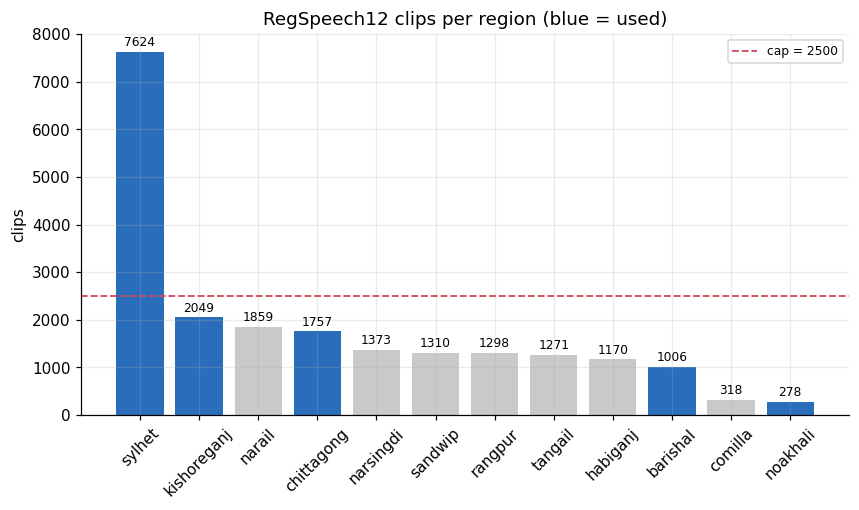

**tables/inventory_official_split_composition.csv** &nbsp; (5 rows)

,region,train,valid,test
0,sylhet,6100,762,762
1,kishoreganj,1639,205,205
2,chittagong,1405,176,176
3,barishal,804,101,101
4,noakhali,222,28,28


**figures/02_official_split_composition.png**

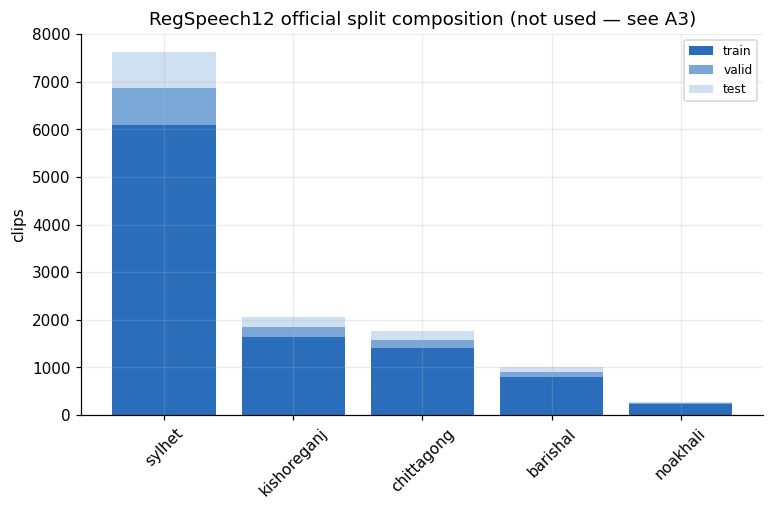

**tables/inventory_class_balance.csv** &nbsp; (6 rows)

,dialect,available,after_cap,source_regions
0,standard,44111,2500,commonvoice
1,chittagong,1757,1757,chittagong
2,mymensingh,2049,2049,kishoreganj
3,barishal,1006,1006,barishal
4,sylhet,7624,2500,sylhet
5,noakhali,278,278,noakhali


**figures/03_class_balance.png**

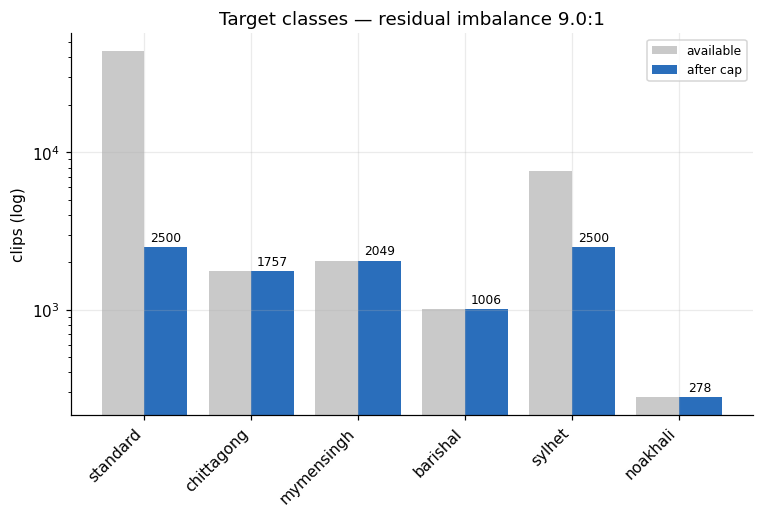

**tables/inventory_durations.csv** &nbsp; (12 rows)

,region,n_sampled,mean_s,median_s,max_s,used
0,barishal,17,16.344941,16.128,22.368,True
1,chittagong,39,17.039077,16.476,30.000,True
2,comilla,8,15.980500,15.854,17.248,False
3,habiganj,19,16.595789,15.516,22.908,False
4,kishoreganj,40,17.035300,16.334,24.860,True
5,narail,29,16.873103,16.164,21.408,False
6,narsingdi,26,16.358615,16.240,20.220,False
7,noakhali,4,14.928000,14.818,19.644,True
8,rangpur,21,16.716223,15.840,23.616,False
9,sandwip,30,16.499200,16.060,20.640,False


**figures/04_durations.png**

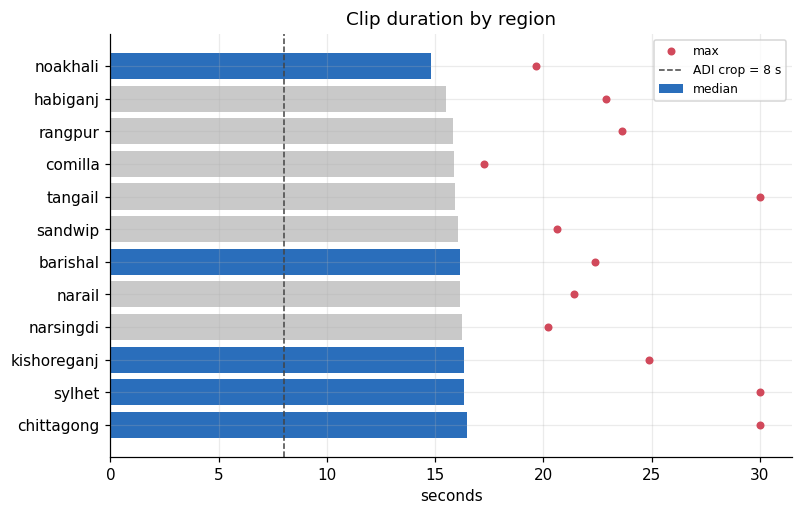

**tables/inventory_summary.csv** &nbsp; (12 rows)

,metric,value
0,total_regspeech12_clips,21313
1,usable_clips_5_regions,12714
2,median_duration_s,16.14
3,sample_rates_hz,16000
4,estimated_total_hours,95.57
5,segmentation_needed,NO
6,speaker_ids_present,NO
7,commonvoice_clips,44111
8,commonvoice_standard_accent_rows,783
9,commonvoice_speakers,11857



  total_regspeech12_clips              21313
  usable_clips_5_regions               12714
  median_duration_s                    16.14
  sample_rates_hz                      16000
  estimated_total_hours                95.57
  segmentation_needed                  NO
  speaker_ids_present                  NO
  commonvoice_clips                    44111
  commonvoice_standard_accent_rows     783
  commonvoice_speakers                 11857
  projected_training_clips             10090
  projected_hours                      45.24


<Figure size 704x528 with 0 Axes>

In [12]:
%cd /kaggle/working
%run plot_01_inventory.py

# A3 — preprocess

In [13]:
%cd /kaggle/working
%run 02_preprocess.py

/kaggle/working
RegSpeech12 usable: 12714 {'barishal': 1006, 'chittagong': 1757, 'mymensingh': 2049, 'noakhali': 278, 'sylhet': 7624}
standard-accent filter: 783 rows

session-block split:
  barishal       33 sessions -> 26 train / 3 val / 4 test
  chittagong     57 sessions -> 45 train / 6 val / 6 test
  mymensingh     66 sessions -> 52 train / 7 val / 7 test
  noakhali        9 sessions -> 7 train / 1 val / 1 test
  standard       54 sessions -> 43 train / 5 val / 6 test
  sylhet        245 sessions -> 196 train / 24 val / 25 test
  500/9616
  1000/9616
  1500/9616
  2000/9616
  2500/9616
  3000/9616
  3500/9616
  4000/9616
  4500/9616
  5000/9616
  5500/9616
  6000/9616
  6500/9616
  7000/9616
  7500/9616
  8000/9616
  8500/9616
  9000/9616
  9500/9616

wrote 6942 rows -> /kaggle/working/manifests/train.jsonl
  train: 6942 clips, 30.12 h, 6942 with text
      standard     594
      chittagong   1410
      mymensingh   1539
      barishal     680
      sylhet       2499
      noakhal

# A4 — shortcut probe 
Measures how much of the dialect classification is reachable from
recording artefacts alone — MFCC means, noise floor, loudness, no linguistic
content.

In [14]:
%cd /kaggle/working
%run 03_shortcut_probe.py

/kaggle/working


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   12.3s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:   14.5s
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:   18.0s
[Parallel(n_jobs=4)]: Done 280 tasks      | elapsed:   22.7s
[Parallel(n_jobs=4)]: Done 442 tasks      | elapsed:   29.0s
[Parallel(n_jobs=4)]: Done 640 tasks      | elapsed:   36.8s
[Parallel(n_jobs=4)]: Done 874 tasks      | elapsed:   45.8s
[Parallel(n_jobs=4)]: Done 1144 tasks      | elapsed:   56.2s
[Parallel(n_jobs=4)]: Done 1450 tasks      | elapsed:  1.1min
[Parallel(n_jobs=4)]: Done 1792 tasks      | elapsed:  1.3min
[Parallel(n_jobs=4)]: Done 2170 tasks      | elapsed:  1.6min
[Parallel(n_jobs=4)]: Done 2584 tasks      | elapsed:  1.9min
[Parallel(n_jobs=4)]: Done 3034 tasks      | elapsed:  2.1min
[Parallel(n_jobs=4)]: Done 3520 tasks      | elapsed:  2.5min
[Parallel(n_jobs=4)]: Done 4000 out of 4000 | elapsed:  2.8min f


=== logreg ===
accuracy 0.7340  macro-F1 0.6138  chance 0.1667
              precision    recall  f1-score   support

    standard       0.95      0.82      0.88       107
  chittagong       0.31      0.22      0.26       150
  mymensingh       0.88      0.83      0.85       272
    barishal       0.66      0.39      0.49       200
      sylhet       0.73      0.94      0.82       625
    noakhali       0.64      0.27      0.38        33

    accuracy                           0.73      1387
   macro avg       0.70      0.58      0.61      1387
weighted avg       0.72      0.73      0.71      1387

[[ 88  11   0   1   7   0]
 [  0  33  15   6  95   1]
 [  0   8 226  10  27   1]
 [  0  35   9  77  76   3]
 [  5  18   7  10 585   0]
 [  0   0   0  13  11   9]]
standard-vs-rest F1: 0.8800

=== rf ===
accuracy 0.7491  macro-F1 0.5727  chance 0.1667
              precision    recall  f1-score   support

    standard       0.96      0.62      0.75       107
  chittagong       0.61      0.36

## A5 — probe figures + tables

/kaggle/working


**tables/probe_headline.csv** &nbsp; (2 rows)

,classifier,accuracy,macro_f1,standard_vs_rest_f1,chance
0,logreg,0.733958,0.613754,0.88,0.166667
1,rf,0.749099,0.572745,0.75,0.166667


**figures/05_probe_headline.png**

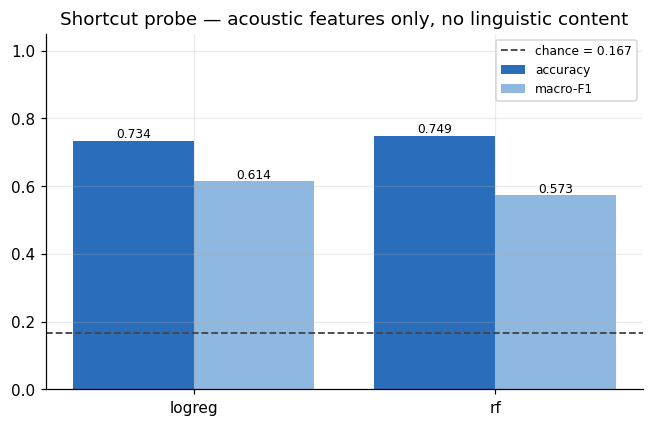

**figures/06_probe_standard_vs_rest.png**

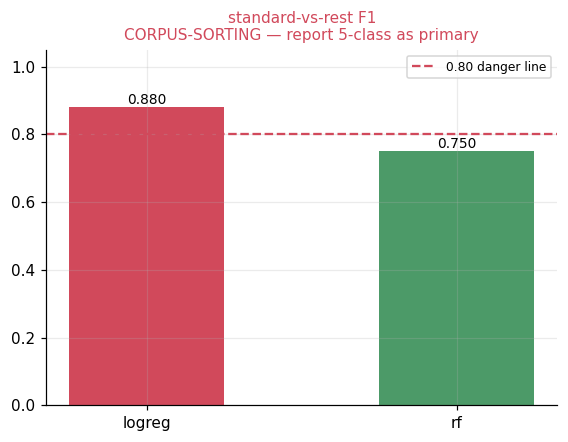

extracting features (~15 min, cached after)


**tables/probe_confusion_matrix.csv** &nbsp; (6 rows)

,standard,chittagong,mymensingh,barishal,sylhet,noakhali
standard,88,11,0,1,7,0
chittagong,0,33,15,6,95,1
mymensingh,0,8,226,10,27,1
barishal,0,35,9,77,76,3
sylhet,5,18,7,10,585,0
noakhali,0,0,0,13,11,9


**tables/probe_per_class.csv** &nbsp; (6 rows)

,dialect,precision,recall,f1,support,corpus_separable
0,standard,0.946237,0.822430,0.880000,107,True
1,chittagong,0.314286,0.220000,0.258824,150,False
2,mymensingh,0.879377,0.830882,0.854442,272,True
3,barishal,0.658120,0.385000,0.485804,200,False
4,sylhet,0.730337,0.936000,0.820477,625,True
5,noakhali,0.642857,0.272727,0.382979,33,False


**figures/07_probe_confusion.png**

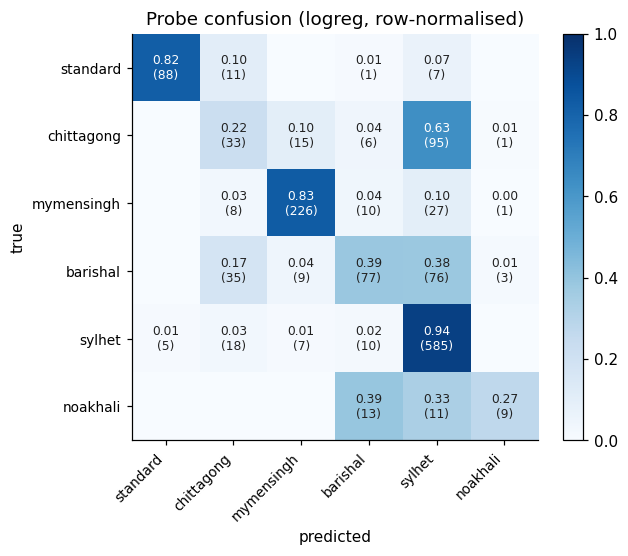

**figures/08_probe_per_class.png**

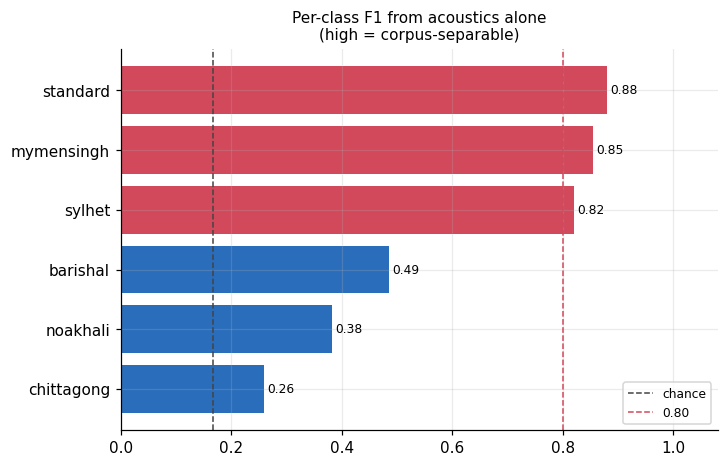

**tables/probe_floor_5class.csv** &nbsp; (2 rows)

,setting,probe_accuracy
0,6-class,0.733958
1,5-class (no standard),0.729412



5-class probe floor (standard excluded): 0.7294

done — figures/ and tables/


<Figure size 704x528 with 0 Axes>

In [15]:
%cd /kaggle/working
%run plot_02_probe.py

# A6 — verify, then Quick Save

In [16]:
import json, os
from pathlib import Path

for m in ["train", "val", "test", "train_asr", "val_asr"]:
    p = Path(f"/kaggle/working/manifests/{m}.jsonl")
    if not p.exists():
        print(f"  MISSING  {m}.jsonl"); continue
    rows = [json.loads(l) for l in open(p) if l.strip()]
    hrs = sum(r.get("duration", 0) for r in rows) / 3600
    ntxt = sum(1 for r in rows if r.get("text"))
    print(f"  {m:10s} {len(rows):6d} clips  {hrs:6.2f} h  {ntxt} with text")

r = json.loads(open("/kaggle/working/manifests/test.jsonl").readline())
print("\n  audio reachable:", os.path.exists(r["audio"]))
!du -sh /kaggle/working/processed /kaggle/working/manifests 2>/dev/null
!rm -rf /kaggle/working/__pycache__

  train        6942 clips   30.12 h  6942 with text
  val          1281 clips    5.67 h  1281 with text
  test         1387 clips    6.01 h  1387 with text
  train_asr   15539 clips   69.41 h  15539 with text
  val_asr      1281 clips    5.67 h  1281 with text

  audio reachable: True
8.8G	/kaggle/working/processed
19M	/kaggle/working/manifests


In [17]:
import glob, os
print("FIGURES"); [print("  ", os.path.basename(f)) for f in sorted(glob.glob("/kaggle/working/figures/*.png"))]
print("TABLES");  [print("  ", os.path.basename(f)) for f in sorted(glob.glob("/kaggle/working/tables/*.csv"))]
!cd /kaggle/working && zip -qr outputs_prep.zip figures tables *.json 2>/dev/null
print("\n-> /kaggle/working/outputs_prep.zip")

FIGURES
   01_region_counts.png
   02_official_split_composition.png
   03_class_balance.png
   04_durations.png
   05_probe_headline.png
   06_probe_standard_vs_rest.png
   07_probe_confusion.png
   08_probe_per_class.png
TABLES
   inventory_class_balance.csv
   inventory_durations.csv
   inventory_official_split_composition.csv
   inventory_region_counts.csv
   inventory_summary.csv
   probe_confusion_matrix.csv
   probe_floor_5class.csv
   probe_headline.csv
   probe_per_class.csv

-> /kaggle/working/outputs_prep.zip
